In [4]:
!nvidia-smi
!nvcc --version

Sat Oct 17 15:50:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
# ============================================================================
#  Prépare les 4 fichiers sources du DE dans /kaggle/working/de
#  Ordre de priorité pour chaque fichier :
#    1. le fichier déjà présent dans /kaggle/working/de, s'il est à jour
#    2. sinon une copie trouvée sous /kaggle/input (dataset), si elle est à jour
#    3. sinon la version embarquée ci-dessous
#  Un fichier est jugé périmé s'il contient un repère d'ancienne version (STALE ci-dessous) :
#  include "kernel.h" inexistant, ancien fitness, cuda_de sans paramètre seed...
#  Tes propres modifications (autres que ces repères) sont donc conservées.
# ============================================================================
import os, glob, shutil

DE = "/kaggle/working/de"
FORCE_EMBEDDED = False      # True : écraser avec les versions embarquées ci-dessous
NAMES = ['kernel_de_seq.h', 'kernel_de_seq.cu', 'kernel_de_seq.cpp', 'main_de_app.cpp']

SOURCES = {}
SOURCES['kernel_de_seq.h'] = r'''#ifndef KERNEL_H
#define KERNEL_H

#include <iostream>
#include <vector>
#include <cmath>
#include <cstdlib>
#include <ctime>
#include <algorithm>
#include <chrono>

// Constante mathématique Pi
const float phi = 3.14159265358979323846f;

// Obtenir le domaine de recherche [min, max] selon la fonction objectif
void get_search_bounds(int obj_func, float &min_val, float &max_val);

// Générateurs de nombres aléatoires
float getRandom(float low, float high);
float getRandomClamped();

// Fonction de Fitness séquentielle
float de_fitness_function(const float* x, int dim, int obj_func);

// Fonction externe qui tourne sur le GPU (implémentée dans kernel_de_seq.cu)
extern "C" void cuda_de(float *positions, float *fitness, float *gBest, float min_val, float max_val, unsigned int seed);

// Algorithme DE Séquentiel principal
void run_de_sequential(int dim, int pop_size, int obj_func, unsigned int seed, float &best_fitness, double &exec_time_ms);

#endif // KERNEL_H'''
SOURCES['kernel_de_seq.cu'] = r'''#include <cuda_runtime.h>
#include <cuda.h>

#include "kernel_de_seq.h"

// 1. La fonction de Fitness (Exactement la même que vous aviez, exécutée sur GPU)
__device__ float fitness_function(float x[]) {
    float res = 0;
    float somme = 0;
    float produit = 1;

    switch (SELECTED_OBJ_FUNC)  {
        case 0: {
            float y1 = 1 + (x[0] - 1)/4;
            float yn = 1 + (x[NUM_OF_DIMENSIONS-1] - 1)/4;
            res += pow(sin(phi*y1), 2);
            for (int i = 0; i < NUM_OF_DIMENSIONS-1; i++) {
                float y = 1 + (x[i] - 1)/4;
                float yp = 1 + (x[i+1] - 1)/4;
                res += pow(y - 1, 2)*(1 + 10*pow(sin(phi*yp), 2));
            }
            res += pow(yn - 1, 2);
            break;
        }
        case 1: 
            for (int i = 0; i < NUM_OF_DIMENSIONS; i++) {
                float zi = x[i] - 0;
                res += pow(zi, 2) - 10*cos(2*phi*zi) + 10;
            }
            res -= 330;
            break;
        case 2:
            for (int i = 0; i < NUM_OF_DIMENSIONS-1; i++) {
                float zi = x[i] - 0 + 1;
                float zip1 = x[i+1] - 0 + 1;
                res += 100 * ( pow(pow(zi, 2) - zip1, 2)) + pow(zi - 1, 2);
            }
            res += 390;
            break;
        case 3:
            for (int i = 0; i < NUM_OF_DIMENSIONS; i++) {
                float zi = x[i] - 0;
                somme += pow(zi, 2)/4000;
                produit *= cos(zi/pow(i+1, 0.5));
            }
            res = somme - produit + 1 - 180; 
            break;
        case 4:
            for(int i = 0; i < NUM_OF_DIMENSIONS; i++) {
                float zi = x[i] - 0;
                res += pow(zi, 2);
            }
            res -= 450;
            break;
    }
    return res;
}

// 2. Générateur de nombres aléatoires sur le GPU (Linear Congruential Generator)
__device__ unsigned int lcg_rand(unsigned int *state) {
    *state = 1664525 * (*state) + 1013904223;
    return *state;
}
__device__ float lcg_rand_float(unsigned int *state) {
    return (float)(lcg_rand(state) & 0xFFFFFF) / (float)0x1000000;
}

// Mélange des bits (finalizer de hash 32 bits) : evite que des seeds ou des iterations
// voisines produisent des flux aleatoires decales ou correles entre eux
__device__ unsigned int hash_u32(unsigned int x) {
    x ^= x >> 16; x *= 0x7feb352dU;
    x ^= x >> 15; x *= 0x846ca68bU;
    x ^= x >> 16;
    return x;
}

// Entier aleatoire dans [0, n) : on prend les bits hauts du LCG
// (les bits bas d'un LCG modulo 2^32 ont une periode tres courte, ex. le bit 0 alterne 0,1,0,1...)
__device__ int lcg_index(unsigned int *state, int n) {
    return (int)((lcg_rand(state) >> 8) % (unsigned int)n);
}

// 3. KERNEL 1 : Mutation et Crossover
__global__ void kernelDEMutationCrossover(float *pop, float *trial, float F, float CR, float min_val, float max_val, int iter, unsigned int seed) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= NUM_OF_PARTICLES) return;

    // Graine unique pour chaque thread : seed utilisateur + ID du thread + itération
    unsigned int state = hash_u32(hash_u32(seed) ^ ((unsigned int)i + 0x9E3779B9u * (unsigned int)iter));

    int r1, r2, r3;
    // Tirage de 3 partenaires distincts
    do { r1 = lcg_index(&state, NUM_OF_PARTICLES); } while (r1 == i);
    do { r2 = lcg_index(&state, NUM_OF_PARTICLES); } while (r2 == i || r2 == r1);
    do { r3 = lcg_index(&state, NUM_OF_PARTICLES); } while (r3 == i || r3 == r1 || r3 == r2);

    int k_rand = lcg_index(&state, NUM_OF_DIMENSIONS); // Croisement garanti

    for (int j = 0; j < NUM_OF_DIMENSIONS; j++) {
        float rand_CR = lcg_rand_float(&state);
        
        if (rand_CR <= CR || j == k_rand) {
            float v = pop[r1 * NUM_OF_DIMENSIONS + j] + F * (pop[r2 * NUM_OF_DIMENSIONS + j] - pop[r3 * NUM_OF_DIMENSIONS + j]);
            // Clamping dans les limites de la fonction
            if (v < min_val) v = min_val;
            if (v > max_val) v = max_val;
            trial[i * NUM_OF_DIMENSIONS + j] = v;
        } else {
            trial[i * NUM_OF_DIMENSIONS + j] = pop[i * NUM_OF_DIMENSIONS + j]; // Héritage direct
        }
    }
}

// 4. KERNEL 2 : Évaluation et Sélection "Survival of the Fittest"
__global__ void kernelDESelection(float *pop, float *trial, float *fitness) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= NUM_OF_PARTICLES) return;

    // Copie locale du vecteur essai pour l'évaluation (évite les appels globaux lents)
    float trial_vec[NUM_OF_DIMENSIONS];
    for (int j = 0; j < NUM_OF_DIMENSIONS; j++) {
        trial_vec[j] = trial[i * NUM_OF_DIMENSIONS + j];
    }

    float trial_fit = fitness_function(trial_vec);

    // Remplacement si la fitness est meilleure
    if (trial_fit <= fitness[i]) {
        for (int j = 0; j < NUM_OF_DIMENSIONS; j++) {
            pop[i * NUM_OF_DIMENSIONS + j] = trial_vec[j];
        }
        fitness[i] = trial_fit;
    }
}

// 5. Fonction principale appelée depuis le C++
extern "C" void cuda_de(float *positions, float *fitness, float *gBest, float min_val, float max_val, unsigned int seed)
{
    int size = NUM_OF_PARTICLES * NUM_OF_DIMENSIONS;
    
    // Déclaration des pointeurs pour la mémoire GPU
    float *devPos;
    float *devTrial;
    float *devFitness;
    
    // Allocation GPU
    cudaMalloc((void**)&devPos, sizeof(float) * size);
    cudaMalloc((void**)&devTrial, sizeof(float) * size);
    cudaMalloc((void**)&devFitness, sizeof(float) * NUM_OF_PARTICLES);
    
    // Copie des données du CPU vers le GPU
    cudaMemcpy(devPos, positions, sizeof(float) * size, cudaMemcpyHostToDevice);
    cudaMemcpy(devFitness, fitness, sizeof(float) * NUM_OF_PARTICLES, cudaMemcpyHostToDevice);
    
    // Configuration de la grille CUDA (1 Thread = 1 Individu)
    int threadsNum = 32;
    int blocksNum = ceil((float)NUM_OF_PARTICLES / threadsNum);
    
    // Paramètres DE
    float F = 0.5f;
    float CR = 0.3f;
    
    // Budget : 10^4 x Dim evaluations au total, initialisation (faite sur le CPU) comprise.
    // On retire donc 1 iteration (= NUM_OF_PARTICLES evaluations) pour egaler le budget du CPU.
    int max_iter = (10000 * NUM_OF_DIMENSIONS) / NUM_OF_PARTICLES - 1;

    for (int iter = 0; iter < max_iter; iter++)
    {     
        // Étape 1 : Créer les nouveaux vecteurs mutants
        kernelDEMutationCrossover<<<blocksNum, threadsNum>>>(devPos, devTrial, F, CR, min_val, max_val, iter, seed);  
        cudaDeviceSynchronize(); // Obligatoire pour s'assurer que la mutation est finie

        // Étape 2 : Évaluer et conserver les meilleurs
        kernelDESelection<<<blocksNum, threadsNum>>>(devPos, devTrial, devFitness);
        cudaDeviceSynchronize();
    }
    
    // Rapatriement de la population et de la fitness finale sur le CPU
    cudaMemcpy(positions, devPos, sizeof(float) * size, cudaMemcpyDeviceToHost);
    cudaMemcpy(fitness, devFitness, sizeof(float) * NUM_OF_PARTICLES, cudaMemcpyDeviceToHost);
    
    // Libération de la mémoire GPU
    cudaFree(devPos);
    cudaFree(devTrial);
    cudaFree(devFitness);

    // Extraction du meilleur individu global (gBest) côté CPU
    float best_fit = fitness[0];
    int best_idx = 0;
    for (int i = 1; i < NUM_OF_PARTICLES; i++) {
        if (fitness[i] < best_fit) {
            best_fit = fitness[i];
            best_idx = i;
        }
    }
    for (int j = 0; j < NUM_OF_DIMENSIONS; j++) {
        gBest[j] = positions[best_idx * NUM_OF_DIMENSIONS + j];
    }
}'''
SOURCES['kernel_de_seq.cpp'] = r'''#include "kernel_de_seq.h"

// Définition des bornes de recherche selon le sujet (slide 5)
void get_search_bounds(int obj_func, float &min_val, float &max_val) {
    switch (obj_func) {
        case 0: // Levy
            min_val = -10.0f; max_val = 10.0f;
            break;
        case 1: // Shifted Rastrigin
            min_val = -5.0f; max_val = 5.0f;
            break;
        case 2: // Shifted Rosenbrock
            min_val = -100.0f; max_val = 100.0f;
            break;
        case 3: // Shifted Griewank
            min_val = -600.0f; max_val = 600.0f;
            break;
        case 4: // Shifted Sphere
            min_val = -100.0f; max_val = 100.0f;
            break;
        default:
            min_val = -100.0f; max_val = 100.0f;
            break;
    }
}

float getRandom(float low, float high) {
    return low + static_cast<float>(rand()) / (static_cast<float>(RAND_MAX / (high - low)));
}

float getRandomClamped() {
    return static_cast<float>(rand()) / static_cast<float>(RAND_MAX);
}

// Évaluation de la fitness selon les formules officielles
float de_fitness_function(const float* x, int dim, int obj_func) {
    float res = 0.0f;

    switch (obj_func) {
        case 0: { // Levy
            float y1 = 1.0f + (x[0] - 1.0f) / 4.0f;
            float yn = 1.0f + (x[dim - 1] - 1.0f) / 4.0f;

            res += std::pow(std::sin(phi * y1), 2);
            for (int i = 0; i < dim - 1; i++) {
                float y = 1.0f + (x[i] - 1.0f) / 4.0f;
                float yp = 1.0f + (x[i + 1] - 1.0f) / 4.0f;
                res += std::pow(y - 1.0f, 2) * (1.0f + 10.0f * std::pow(std::sin(phi * yp), 2));
            }
            res += std::pow(yn - 1.0f, 2);
            break;
        }
        case 1: { // Shifted Rastrigin (Global Optimum = -330)
            for (int i = 0; i < dim; i++) {
                float zi = x[i];
                res += (zi * zi) - 10.0f * std::cos(2.0f * phi * zi) + 10.0f;
            }
            res -= 330.0f;
            break;
        }
        case 2: { // Shifted Rosenbrock (Global Optimum = 390)
            for (int i = 0; i < dim - 1; i++) {
                float zi = x[i] + 1.0f;
                float zip1 = x[i + 1] + 1.0f;
                res += 100.0f * std::pow((zi * zi - zip1), 2) + std::pow(zi - 1.0f, 2);
            }
            res += 390.0f;
            break;
        }
        case 3: { // Shifted Griewank (Global Optimum = -180)
            float somme = 0.0f;
            float produit = 1.0f;
            for (int i = 0; i < dim; i++) {
                float zi = x[i];
                somme += (zi * zi) / 4000.0f;
                produit *= std::cos(zi / std::sqrt(static_cast<float>(i + 1)));
            }
            res = somme - produit + 1.0f - 180.0f;
            break;
        }
        case 4: { // Shifted Sphere (Global Optimum = -450)
            for (int i = 0; i < dim; i++) {
                float zi = x[i];
                res += zi * zi;
            }
            res -= 450.0f;
            break;
        }
    }
    return res;
}

// DE/rand/1/bin Séquentiel (CPU)
void run_de_sequential(int dim, int pop_size, int obj_func, unsigned int seed, float &best_fitness, double &exec_time_ms) {
    srand(seed);

    float min_val, max_val;
    get_search_bounds(obj_func, min_val, max_val);

    const float F = 0.5f;   // Paramètre de Mutation
    const float CR = 0.3f;  // Paramètre de Crossover
    const long max_fes = 10000L * dim; // Budget officiel d'évaluations

    std::vector<float> pop(pop_size * dim);
    std::vector<float> fitness(pop_size);
    std::vector<float> trial(dim);
    std::vector<float> gBest(dim);
    float gBestFitness = 1e30f;

    // 1. Initialisation de la population dans les vraies bornes de la fonction
    for (int i = 0; i < pop_size; i++) {
        for (int j = 0; j < dim; j++) {
            pop[i * dim + j] = getRandom(min_val, max_val);
        }
        fitness[i] = de_fitness_function(&pop[i * dim], dim, obj_func);

        if (fitness[i] < gBestFitness) {
            gBestFitness = fitness[i];
            for (int j = 0; j < dim; j++) gBest[j] = pop[i * dim + j];
        }
    }

    long fes = pop_size; // Évaluations initiales faites

    auto start_time = std::chrono::high_resolution_clock::now();

    // 2. Boucle principale du DE
    while (fes < max_fes) {
        for (int i = 0; i < pop_size; i++) {
            // Sélection de 3 individus distincts r1 != r2 != r3 != i
            int r1, r2, r3;
            do { r1 = rand() % pop_size; } while (r1 == i);
            do { r2 = rand() % pop_size; } while (r2 == i || r2 == r1);
            do { r3 = rand() % pop_size; } while (r3 == i || r3 == r1 || r3 == r2);

            int k_rand = rand() % dim; // Au moins un gène muté

            // Mutation + Crossover (DE/rand/1/bin)
            for (int j = 0; j < dim; j++) {
                if (getRandomClamped() <= CR || j == k_rand) {
                    float v = pop[r1 * dim + j] + F * (pop[r2 * dim + j] - pop[r3 * dim + j]);
                    // Clamping dans les bornes autorisées
                    if (v < min_val) v = min_val;
                    if (v > max_val) v = max_val;
                    trial[j] = v;
                } else {
                    trial[j] = pop[i * dim + j];
                }
            }

            // Évaluation du vecteur essai
            float trial_fitness = de_fitness_function(trial.data(), dim, obj_func);
            fes++;

            // Remplacement si meilleur ou égal (Sélection)
            if (trial_fitness <= fitness[i]) {
                for (int j = 0; j < dim; j++) pop[i * dim + j] = trial[j];
                fitness[i] = trial_fitness;

                if (trial_fitness < gBestFitness) {
                    gBestFitness = trial_fitness;
                    for (int j = 0; j < dim; j++) gBest[j] = trial[j];
                }
            }

            if (fes >= max_fes) break;
        }
    }

    auto end_time = std::chrono::high_resolution_clock::now();
    exec_time_ms = std::chrono::duration<double, std::milli>(end_time - start_time).count();
    best_fitness = gBestFitness;
}'''
SOURCES['main_de_app.cpp'] = r'''#include "kernel_de_seq.h"
#include <string>
#include <chrono>

int main(int argc, char** argv) {
    // On attend 6 arguments maintenant : le nom du programme + 5 paramètres
    if (argc < 6) { 
        std::cout << "Usage: " << argv[0] << " <mode> <dim> <pop> <obj_func> <seed>" << std::endl;
        return 1;
    }

    std::string mode = argv[1];
    int dim = std::stoi(argv[2]);
    int pop = std::stoi(argv[3]);
    int obj_func = std::stoi(argv[4]);
    unsigned int seed = std::stoul(argv[5]);

    float best_fitness = 0.0f;
    double exec_time_ms = 0.0;

    if (mode == "cpu") {
        // --- Exécution du mode CPU (Séquentiel) ---
        run_de_sequential(dim, pop, obj_func, seed, best_fitness, exec_time_ms);
        
        std::cout << "Mode: cpu | Dim: " << dim << " | Pop: " << pop 
                  << " | ObjFunc: " << obj_func << " | Best Fitness: " << best_fitness 
                  << " | FEs: " << (10000 * dim) << " | Time: " << exec_time_ms << " ms\n";
    } 
    else if (mode == "gpu") {
        // --- Exécution du mode GPU (CUDA) ---
        srand(seed);
        float min_val, max_val;
        get_search_bounds(obj_func, min_val, max_val);

        std::vector<float> pop_positions(pop * dim);
        std::vector<float> pop_fitness(pop);
        std::vector<float> gBest(dim);
        
        // Initialisation sur le CPU
        for (int i = 0; i < pop; i++) {
            for (int j = 0; j < dim; j++) {
                pop_positions[i * dim + j] = getRandom(min_val, max_val);
            }
            pop_fitness[i] = de_fitness_function(&pop_positions[i * dim], dim, obj_func);
        }

        auto start_time = std::chrono::high_resolution_clock::now();
        
        // Appel de la fonction CUDA
        cuda_de(pop_positions.data(), pop_fitness.data(), gBest.data(), min_val, max_val, seed);
        
        auto end_time = std::chrono::high_resolution_clock::now();
        exec_time_ms = std::chrono::duration<double, std::milli>(end_time - start_time).count();

        // Récupération de la meilleure fitness
        best_fitness = pop_fitness[0];
        for (int i = 1; i < pop; i++) {
            if (pop_fitness[i] < best_fitness) best_fitness = pop_fitness[i];
        }

        std::cout << "Mode: gpu | Dim: " << dim << " | Pop: " << pop 
                  << " | ObjFunc: " << obj_func << " | Best Fitness: " << best_fitness 
                  << " | FEs: " << (10000 * dim) << " | Time: " << exec_time_ms << " ms\n";
    } 
    else {
        std::cout << "Erreur : Mode '" << mode << "' non supporte." << std::endl;
        return 1;
    }

    return 0;
}'''

STALE = {
    'kernel_de_seq.h':   ['float max_val);'],
    'kernel_de_seq.cu':  ['"kernel.h"', 'math_functions.h', 'float produit = 0', '198491317'],
    'kernel_de_seq.cpp': ['"kernel.h"'],
    'main_de_app.cpp':   ['"kernel.h"', 'gBest.data(), min_val, max_val);'],
}
def stale(path, n):
    txt = open(path, encoding="utf-8", errors="ignore").read()
    return any(m in txt for m in STALE[n])

os.makedirs(DE, exist_ok=True)
for n in NAMES:
    dst = f"{DE}/{n}"
    if not FORCE_EMBEDDED and os.path.exists(dst) and not stale(dst, n):
        print(f"{n:18s} : fichier existant utilisé")
        continue
    found = [] if FORCE_EMBEDDED else [p for p in glob.glob(f"/kaggle/input/**/{n}", recursive=True) if not stale(p, n)]
    if found:
        shutil.copy(found[0], dst)
        print(f"{n:18s} : copié depuis {found[0]}")
    else:
        with open(dst, "w", encoding="utf-8") as f:
            f.write(SOURCES[n])
        print(f"{n:18s} : version embarquée écrite")

kernel_de_seq.h    : copié depuis /kaggle/input/datasets/rayhansaouir/dataset1/kernel_de_seq.h
kernel_de_seq.cu   : copié depuis /kaggle/input/datasets/rayhansaouir/dataset1/kernel_de_seq.cu
kernel_de_seq.cpp  : copié depuis /kaggle/input/datasets/rayhansaouir/dataset1/kernel_de_seq.cpp
main_de_app.cpp    : copié depuis /kaggle/input/datasets/rayhansaouir/dataset1/main_de_app.cpp


In [8]:
%%time
# Sweep du DE : dim {10,50,100} x pop {50,100,500} x 4 fonctions, en CPU et en GPU
# Équivalent de :  !./pso --sweep --runs 10 --out results_pso.csv | tee summary_pso.txt
import re, subprocess, itertools
import numpy as np, pandas as pd

DE = "/kaggle/working/de"
RUNS = 10
DIMS, POPS = [10, 50, 100], [50, 100, 500]
FUNCS = {4: "Sphere", 1: "Rastrigin", 2: "Rosenbrock", 3: "Griewank"}
BIAS = {4: -450.0, 1: -330.0, 2: 390.0, 3: -180.0}
OUT_CSV, OUT_TXT = "/kaggle/working/results_de.csv", "/kaggle/working/summary_de.txt"
COLS = ["algo", "func", "dim", "pop", "run", "seed", "best", "error", "time_ms"]

def sh(cmd):
    r = subprocess.run(cmd, cwd=DE, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(" ".join(cmd) + "\n" + (r.stderr or r.stdout))
    return r.stdout

txt = open(OUT_TXT, "w")
def log(line):                       # affiche ET écrit dans summary_de.txt (comme tee)
    print(line)
    txt.write(line + "\n"); txt.flush()

# Parties CPU compilées une seule fois ; le .cu est recompilé par configuration
sh(["g++", "-O2", "-c", "kernel_de_seq.cpp", "-o", "k_cpp.o"])
sh(["g++", "-O2", "-c", "main_de_app.cpp", "-o", "main.o"])

log(f"{'algo':7s} {'function':10s} {'dim':>4s} {'pop':>4s} {'runs':>4s} | {'mean':>14s} {'std':>14s} "
    f"{'best':>14s} {'mean_error':>14s} | {'time_ms':>10s}")
rows = []
for dim, pop, f in itertools.product(DIMS, POPS, FUNCS):
    sh(["nvcc", "-O2", "-arch=native", f"-DNUM_OF_DIMENSIONS={dim}", f"-DNUM_OF_PARTICLES={pop}",
        f"-DSELECTED_OBJ_FUNC={f}", "-c", "kernel_de_seq.cu", "-o", "k_cu.o"])
    sh(["nvcc", "-arch=native", "main.o", "k_cpp.o", "k_cu.o", "-o", "de_app"])
    for mode in ("cpu", "gpu"):
        best, ms = [], []
        for seed in range(1, RUNS + 1):
            out = sh(["./de_app", mode, str(dim), str(pop), str(f), str(seed)])
            best.append(float(re.search(r"Best Fitness:\s*(\S+)", out).group(1)))
            ms.append(float(re.search(r"Time:\s*(\S+)\s*ms", out).group(1)))
            rows.append((f"DE {mode}", FUNCS[f], dim, pop, seed - 1, seed, best[-1], best[-1] - BIAS[f], ms[-1]))
        b = np.array(best)
        log(f"{'DE ' + mode:7s} {FUNCS[f]:10s} {dim:4d} {pop:4d} {RUNS:4d} | {b.mean():14.6e} "
            f"{b.std(ddof=1):14.6e} {b.min():14.6e} {b.mean() - BIAS[f]:14.6e} | {np.mean(ms):10.2f}")
    pd.DataFrame(rows, columns=COLS).to_csv(OUT_CSV, index=False)   # sauvegarde à chaque configuration
txt.close()
print(f"\n{len(rows)} exécutions -> {OUT_CSV} et {OUT_TXT}")

algo    function    dim  pop runs |           mean            std           best     mean_error |    time_ms
DE cpu  Sphere       10   50   10 |  -4.500000e+02   0.000000e+00  -4.500000e+02   0.000000e+00 |      30.26
DE gpu  Sphere       10   50   10 |  -4.500000e+02   0.000000e+00  -4.500000e+02   0.000000e+00 |     414.06
DE cpu  Rastrigin    10   50   10 |  -3.300000e+02   0.000000e+00  -3.300000e+02   0.000000e+00 |      35.07
DE gpu  Rastrigin    10   50   10 |  -3.300000e+02   0.000000e+00  -3.300000e+02   0.000000e+00 |     412.36
DE cpu  Rosenbrock   10   50   10 |   3.907173e+02   1.631223e+00   3.900030e+02   7.173000e-01 |      31.19
DE gpu  Rosenbrock   10   50   10 |   3.920896e+02   2.101295e+00   3.900010e+02   2.089600e+00 |     438.50
DE cpu  Griewank     10   50   10 |  -1.800000e+02   0.000000e+00  -1.800000e+02   0.000000e+00 |      38.13
DE gpu  Griewank     10   50   10 |  -1.800000e+02   0.000000e+00  -1.800000e+02   0.000000e+00 |     421.33
DE cpu  Sphere     

In [9]:
df_de = pd.read_csv("results_de.csv") 
df_de["success"] = df_de["error"] < 1e-8

summary_de = (df_de.groupby(["algo", "func", "dim", "pop"])
                 .agg(mean_best=("best", "mean"), std_best=("best", "std"),
                      min_best=("best", "min"), mean_error=("error", "mean"),
                      std_error=("error", "std"), success_rate=("success", "mean"),
                      time_s=("time_ms", lambda s: s.mean() / 1000.0))
                 .reset_index())

# Sauvegarde dans le fichier summary_de.csv
summary_de.to_csv("/kaggle/working/summary_de.csv", index=False)
summary_de


,algo,func,dim,pop,mean_best,std_best,min_best,mean_error,std_error,success_rate,time_s
0,DE cpu,Griewank,10,50,-180.00000,0.000000,-180.0000,0.00000,0.000000,1.0,0.038132
1,DE cpu,Griewank,10,100,-180.00000,0.000000,-180.0000,0.00000,0.000000,1.0,0.039248
2,DE cpu,Griewank,10,500,-179.84330,0.016337,-179.8760,0.15670,0.016337,0.0,0.045771
3,DE cpu,Griewank,50,50,-180.00000,0.000000,-180.0000,0.00000,0.000000,1.0,0.789520
4,DE cpu,Griewank,50,100,-180.00000,0.000000,-180.0000,0.00000,0.000000,1.0,0.790708
5,DE cpu,Griewank,50,500,-180.00000,0.000000,-180.0000,0.00000,0.000000,1.0,0.825050
6,DE cpu,Griewank,100,50,-180.00000,0.000000,-180.0000,0.00000,0.000000,1.0,3.085066
7,DE cpu,Griewank,100,100,-180.00000,0.000000,-180.0000,0.00000,0.000000,1.0,3.017101
8,DE cpu,Griewank,100,500,-179.92140,0.005602,-179.9310,0.07860,0.005602,0.0,3.372873
9,DE cpu,Rastrigin,10,50,-330.00000,0.000000,-330.0000,0.00000,0.000000,1.0,0.035065


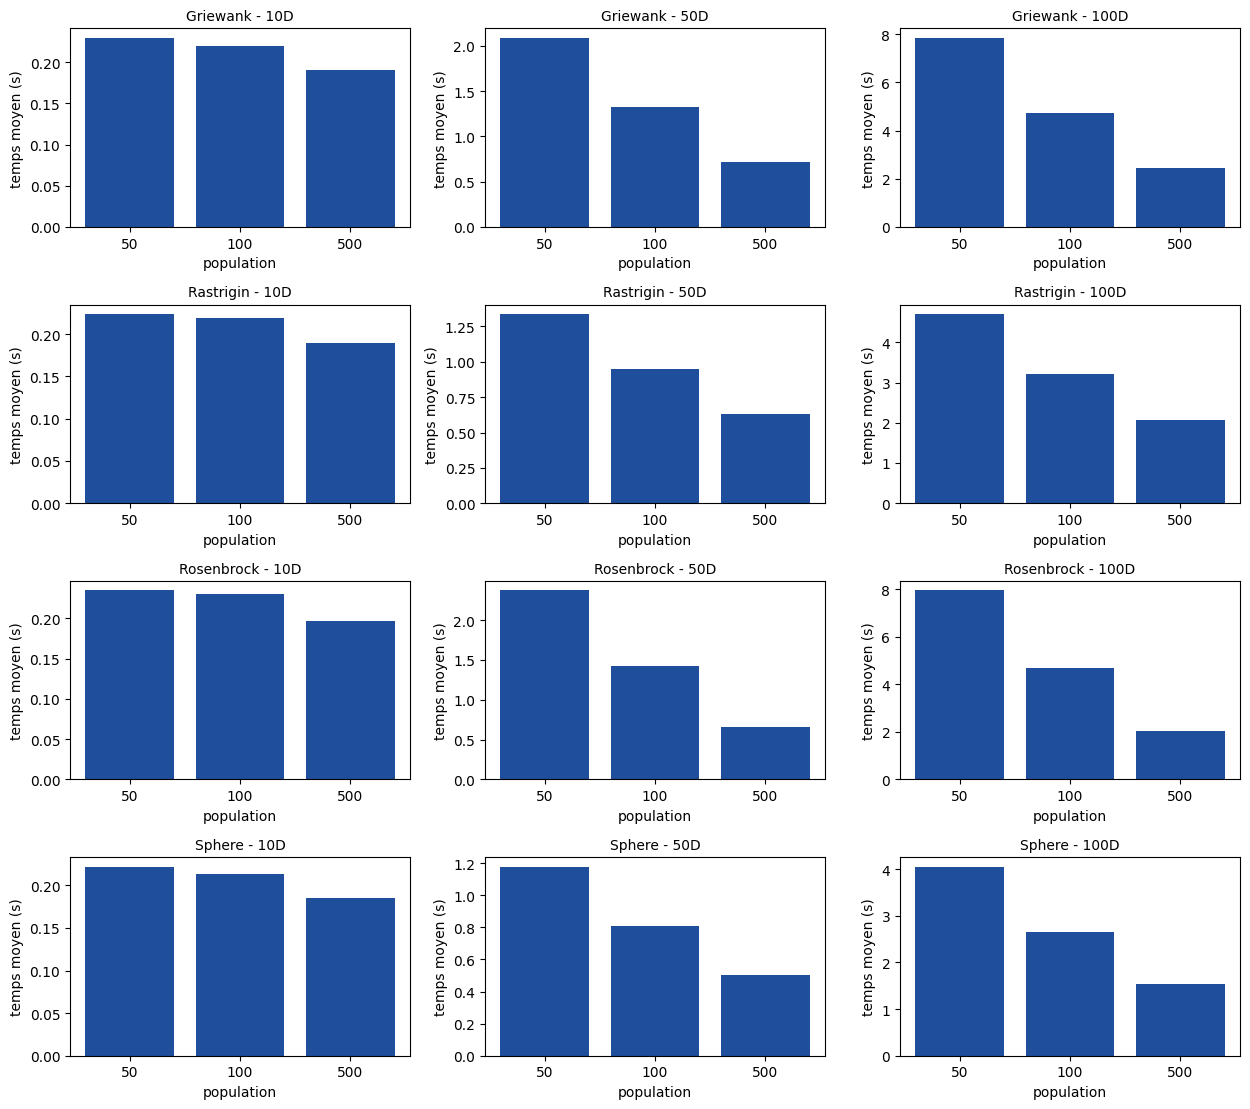

In [11]:
import matplotlib.pyplot as plt

funcs = list(summary_de["func"].unique())
dims = sorted(summary_de["dim"].unique())
pops = sorted(summary_de["pop"].unique())

fig, axes = plt.subplots(len(funcs), len(dims), figsize=(4.2 * len(dims), 2.8 * len(funcs)), squeeze=False)

for i, f in enumerate(funcs):
    for j, d in enumerate(dims):
        # Filter for the specific function and dimension
        subset = summary_de[(summary_de.func == f) & (summary_de.dim == d)]
        
        # Group by 'pop' and calculate the mean to combine duplicate rows
        s = subset.groupby("pop").mean(numeric_only=True).reindex(pops)
        
        ax = axes[i][j]
        ax.bar([str(p) for p in pops], s["time_s"], color="#1f4e9c")
        ax.set_title(f"{f} - {d}D", fontsize=10)
        ax.set_xlabel("population")
        ax.set_ylabel("temps moyen (s)")

plt.tight_layout()
plt.savefig("fig_time_vs_pop.png", dpi=200)
plt.show()

In [12]:
# ============================================================================
#  Prépare les 4 fichiers sources du PSO dans /kaggle/working/pso
#  Ordre de priorité pour chaque fichier :
#    1. le fichier déjà présent dans /kaggle/working/pso, s'il est à jour
#    2. sinon une copie trouvée sous /kaggle/input (dataset), si elle est à jour
#    3. sinon la version embarquée ci-dessous
#  Un fichier est jugé périmé s'il contient un repère d'ancienne version (STALE ci-dessous).
#  Tes propres modifications (autres que ces repères) sont donc conservées.
# ============================================================================
import os, glob, shutil

PSO_DIR = "/kaggle/working/pso"
FORCE_EMBEDDED = False      # True : écraser avec les versions embarquées ci-dessous
NAMES = ['kernel_pso_seq.h', 'kernel_pso_seq.cu', 'kernel_pso_seq.cpp', 'main_pso_seq.cpp']

SOURCES = {}

# --- Insérez ici le code source réel de votre PSO entre les triples guillemets ---
SOURCES['kernel_pso_seq.h'] = r'''// TODO: Collez le code de kernel_pso_seq.h ici
#ifndef KERNEL_PSO_H
#define KERNEL_PSO_H
// ...
#endif
'''

SOURCES['kernel_pso_seq.cu'] = r'''// TODO: Collez le code de kernel_pso_seq.cu ici
'''

SOURCES['kernel_pso_seq.cpp'] = r'''// TODO: Collez le code de kernel_pso_seq.cpp ici
'''

SOURCES['main_pso_seq.cpp'] = r'''// TODO: Collez le code de main_pso_seq.cpp ici
'''

# Modifiez ces chaînes de caractères par des bouts de code de vos anciennes versions
# que vous souhaitez détecter et écraser (ou laissez vide si inutile).
STALE = {
    'kernel_pso_seq.h':   ['/* REPERE_ANCIENNE_VERSION_A_CHANGER */'],
    'kernel_pso_seq.cu':  ['/* REPERE_ANCIENNE_VERSION_A_CHANGER */'],
    'kernel_pso_seq.cpp': ['/* REPERE_ANCIENNE_VERSION_A_CHANGER */'],
    'main_pso_seq.cpp':   ['/* REPERE_ANCIENNE_VERSION_A_CHANGER */'],
}

def stale(path, n):
    txt = open(path, encoding="utf-8", errors="ignore").read()
    # Si STALE[n] est vide, ça ne sera jamais stale (retourne False)
    if not STALE[n]: 
        return False
    return any(m in txt for m in STALE[n])

os.makedirs(PSO_DIR, exist_ok=True)

for n in NAMES:
    dst = f"{PSO_DIR}/{n}"
    
    # 1. Vérification dans le dossier de travail Kaggle
    if not FORCE_EMBEDDED and os.path.exists(dst) and not stale(dst, n):
        print(f"{n:18s} : fichier existant utilisé")
        continue
        
    # 2. Recherche dans les inputs / datasets de Kaggle
    found = [] if FORCE_EMBEDDED else [p for p in glob.glob(f"/kaggle/input/**/{n}", recursive=True) if not stale(p, n)]
    
    if found:
        shutil.copy(found[0], dst)
        print(f"{n:18s} : copié depuis {found[0]}")
    else:
        # 3. Création à partir de la variable SOURCES ci-dessus
        with open(dst, "w", encoding="utf-8") as f:
            f.write(SOURCES[n])
        print(f"{n:18s} : version embarquée écrite")

kernel_pso_seq.h   : copié depuis /kaggle/input/datasets/rayhansaouir/dataset1/kernel_pso_seq.h
kernel_pso_seq.cu  : copié depuis /kaggle/input/datasets/rayhansaouir/dataset1/kernel_pso_seq.cu
kernel_pso_seq.cpp : copié depuis /kaggle/input/datasets/rayhansaouir/dataset1/kernel_pso_seq.cpp
main_pso_seq.cpp   : copié depuis /kaggle/input/datasets/rayhansaouir/dataset1/main_pso_seq.cpp


In [14]:
%%time
# ============================================================================
#  Sweep du PSO CPU : dim {10,50,100} x pop {50,100,500} x 4 fonctions, RUNS runs chacun
#  Équivalent de :  !./pso_seq --sweep --runs 10 --out results_pso.csv | tee summary_pso.txt
#  Seuls 3 fichiers servent au PSO CPU ; kernel_pso_seq.cu n'est pas utilisé (aucun PSO GPU).
#  Pour chaque fichier : 1) celui déjà dans /kaggle/working/pso s'il est à jour,
#  2) sinon une copie à jour trouvée sous /kaggle/input, 3) sinon la version embarquée.
# ============================================================================
import os, glob, shutil, re, subprocess, itertools
import numpy as np, pandas as pd

PSO = "/kaggle/working/pso"
RUNS = 10
DIMS, POPS = [10, 50, 100], [50, 100, 500]
FUNCS = {4: "Sphere", 1: "Rastrigin", 2: "Rosenbrock", 3: "Griewank"}
BIAS = {4: -450.0, 1: -330.0, 2: 390.0, 3: -180.0}
OUT_CSV, OUT_TXT = "/kaggle/working/results_pso.csv", "/kaggle/working/summary_pso.txt"
COLS = ["algo", "func", "dim", "pop", "run", "seed", "best", "error", "time_ms"]
NAMES = ['kernel_pso_seq.h', 'kernel_pso_seq.cpp', 'main_pso_seq.cpp']
STALE = {'kernel_pso_seq.h': [], 'kernel_pso_seq.cpp': ['"kernel.h"'], 'main_pso_seq.cpp': ['"kernel.h"']}

SOURCES = {}
SOURCES['kernel_pso_seq.h'] = r'''#ifndef KERNEL_H
#define KERNEL_H

#include <iostream>
#include <vector>
#include <cmath>
#include <cstdlib>
#include <ctime>
#include <chrono>

// Constantes Mathématiques & PSO
const float phi = 3.14159265358979323846f;
const float OMEGA = 0.5f;
const float c1 = 1.5f;
const float c2 = 1.5f;

// Fonctions utilitaires
void get_search_bounds(int obj_func, float &min_val, float &max_val);
float getRandom(float low, float high);
float getRandomClamped();

// Fonction d'évaluation (Fitness)
float pso_fitness_function(const float* x, int dim, int obj_func);

// Algorithme PSO Séquentiel principal
void run_pso_sequential(int dim, int pop_size, int obj_func, unsigned int seed, float &best_fitness, double &exec_time_ms);

#endif // KERNEL_H'''
SOURCES['kernel_pso_seq.cpp'] = r'''#include "kernel_pso_seq.h"

// 1. Définition des bornes selon la fonction (Crucial pour la correction)
void get_search_bounds(int obj_func, float &min_val, float &max_val) {
    switch (obj_func) {
        case 0: min_val = -10.0f; max_val = 10.0f; break; // Levy
        case 1: min_val = -5.0f; max_val = 5.0f; break;   // Rastrigin
        case 2: min_val = -100.0f; max_val = 100.0f; break; // Rosenbrock
        case 3: min_val = -600.0f; max_val = 600.0f; break; // Griewank
        case 4: min_val = -100.0f; max_val = 100.0f; break; // Sphere
        default: min_val = -100.0f; max_val = 100.0f; break;
    }
}

float getRandom(float low, float high) {
    return low + static_cast<float>(rand()) / (static_cast<float>(RAND_MAX / (high - low)));
}

float getRandomClamped() {
    return static_cast<float>(rand()) / static_cast<float>(RAND_MAX);
}

// 2. Évaluation de la fitness (identique, formules corrigées)
float pso_fitness_function(const float* x, int dim, int obj_func) {
    float res = 0.0f;
    switch (obj_func) {
        case 0: { 
            float y1 = 1.0f + (x[0] - 1.0f) / 4.0f;
            float yn = 1.0f + (x[dim - 1] - 1.0f) / 4.0f;
            res += std::pow(std::sin(phi * y1), 2);
            for (int i = 0; i < dim - 1; i++) {
                float y = 1.0f + (x[i] - 1.0f) / 4.0f;
                float yp = 1.0f + (x[i + 1] - 1.0f) / 4.0f;
                res += std::pow(y - 1.0f, 2) * (1.0f + 10.0f * std::pow(std::sin(phi * yp), 2));
            }
            res += std::pow(yn - 1.0f, 2);
            break;
        }
        case 1: { 
            for (int i = 0; i < dim; i++) {
                res += (x[i] * x[i]) - 10.0f * std::cos(2.0f * phi * x[i]) + 10.0f;
            }
            res -= 330.0f;
            break;
        }
        case 2: { 
            for (int i = 0; i < dim - 1; i++) {
                float zi = x[i] + 1.0f;
                float zip1 = x[i + 1] + 1.0f;
                res += 100.0f * std::pow((zi * zi - zip1), 2) + std::pow(zi - 1.0f, 2);
            }
            res += 390.0f;
            break;
        }
        case 3: { 
            float somme = 0.0f;
            float produit = 1.0f;
            for (int i = 0; i < dim; i++) {
                somme += (x[i] * x[i]) / 4000.0f;
                produit *= std::cos(x[i] / std::sqrt(static_cast<float>(i + 1)));
            }
            res = somme - produit + 1.0f - 180.0f;
            break;
        }
        case 4: { 
            for (int i = 0; i < dim; i++) {
                res += x[i] * x[i];
            }
            res -= 450.0f;
            break;
        }
    }
    return res;
}

// 3. Implémentation du PSO Séquentiel
void run_pso_sequential(int dim, int pop_size, int obj_func, unsigned int seed, float &best_fitness, double &exec_time_ms) {
    srand(seed);

    float min_val, max_val;
    get_search_bounds(obj_func, min_val, max_val);

    const long max_fes = 10000L * dim; // Budget officiel d'évaluations

    std::vector<float> pop(pop_size * dim);
    std::vector<float> velocities(pop_size * dim, 0.0f);
    
    std::vector<float> pBests(pop_size * dim);
    std::vector<float> pBestFitnesses(pop_size);
    
    std::vector<float> gBest(dim);
    float gBestFitness = 1e30f;

    // A. Initialisation des particules
    for (int i = 0; i < pop_size; i++) {
        for (int j = 0; j < dim; j++) {
            pop[i * dim + j] = getRandom(min_val, max_val);
            pBests[i * dim + j] = pop[i * dim + j];
        }
        pBestFitnesses[i] = pso_fitness_function(&pop[i * dim], dim, obj_func);

        if (pBestFitnesses[i] < gBestFitness) {
            gBestFitness = pBestFitnesses[i];
            for (int j = 0; j < dim; j++) gBest[j] = pop[i * dim + j];
        }
    }

    long fes = pop_size;

    auto start_time = std::chrono::high_resolution_clock::now();

    // B. Boucle principale du PSO
    while (fes < max_fes) {
        for (int i = 0; i < pop_size; i++) {
            
            // Mise à jour de la vitesse et de la position
            for (int j = 0; j < dim; j++) {
                float r1 = getRandomClamped();
                float r2 = getRandomClamped();
                
                int idx = i * dim + j;
                
                // Formule PSO
                velocities[idx] = OMEGA * velocities[idx] + 
                                  c1 * r1 * (pBests[idx] - pop[idx]) + 
                                  c2 * r2 * (gBest[j] - pop[idx]);
                
                pop[idx] += velocities[idx];
                
                // Clamping strict dans les bornes autorisées
                if (pop[idx] < min_val) {
                    pop[idx] = min_val;
                    velocities[idx] = 0.0f; // Stoppe la particule si elle heurte le bord
                }
                if (pop[idx] > max_val) {
                    pop[idx] = max_val;
                    velocities[idx] = 0.0f;
                }
            }

            // Évaluation de la nouvelle position
            float current_fitness = pso_fitness_function(&pop[i * dim], dim, obj_func);
            fes++;

            // Mise à jour du meilleur personnel (pBest)
            if (current_fitness < pBestFitnesses[i]) {
                pBestFitnesses[i] = current_fitness;
                for (int j = 0; j < dim; j++) pBests[i * dim + j] = pop[i * dim + j];

                // Mise à jour du meilleur global (gBest)
                if (current_fitness < gBestFitness) {
                    gBestFitness = current_fitness;
                    for (int j = 0; j < dim; j++) gBest[j] = pop[i * dim + j];
                }
            }

            if (fes >= max_fes) break;
        }
    }

    auto end_time = std::chrono::high_resolution_clock::now();
    exec_time_ms = std::chrono::duration<double, std::milli>(end_time - start_time).count();
    best_fitness = gBestFitness;
}'''
SOURCES['main_pso_seq.cpp'] = r'''#include "kernel_pso_seq.h"

int main(int argc, char** argv) {
    if (argc < 5) {
        std::cout << "Usage: " << argv[0] << " <dim> <pop> <obj_func> <seed>" << std::endl;
        std::cout << "  dim      : 10, 50, 100" << std::endl;
        std::cout << "  pop      : 50, 100, 500" << std::endl;
        std::cout << "  obj_func : 0 (Levy), 1 (Rastrigin), 2 (Rosenbrock), 3 (Griewank), 4 (Sphere)" << std::endl;
        std::cout << "  seed     : Nombre entier (ex: 1)" << std::endl;
        return 1;
    }

    int dim = std::stoi(argv[1]);
    int pop = std::stoi(argv[2]);
    int obj_func = std::stoi(argv[3]);
    unsigned int seed = std::stoul(argv[4]);

    float best_fitness = 0.0f;
    double exec_time_ms = 0.0;

    run_pso_sequential(dim, pop, obj_func, seed, best_fitness, exec_time_ms);

    std::cout << "Mode: cpu (PSO) | Dim: " << dim 
              << " | Pop: " << pop 
              << " | ObjFunc: " << obj_func 
              << " | Best Fitness: " << best_fitness 
              << " | FEs: " << (10000 * dim) 
              << " | Time: " << exec_time_ms << " ms" << std::endl;

    return 0;
}'''

# ---------------------------------------------------------------- 1) fichiers sources
def stale(path, n):
    txt = open(path, encoding="utf-8", errors="ignore").read()
    return any(m in txt for m in STALE[n])

os.makedirs(PSO, exist_ok=True)
for n in NAMES:
    dst = f"{PSO}/{n}"
    if os.path.exists(dst) and not stale(dst, n):
        print(f"{n:20s} : fichier existant utilisé"); continue
    found = [p for p in glob.glob(f"/kaggle/input/**/{n}", recursive=True) if not stale(p, n)]
    if found:
        shutil.copy(found[0], dst); print(f"{n:20s} : copié depuis {found[0]}")
    else:
        with open(dst, "w", encoding="utf-8") as f:
            f.write(SOURCES[n])
        print(f"{n:20s} : version embarquée écrite")

# ---------------------------------------------------------------- 2) compilation (CPU seulement)
def sh(cmd):
    r = subprocess.run(cmd, cwd=PSO, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(" ".join(cmd) + "\n" + (r.stderr or r.stdout))
    return r.stdout

sh(["g++", "-O2", "main_pso_seq.cpp", "kernel_pso_seq.cpp", "-o", "pso_seq"])

# ---------------------------------------------------------------- 3) sweep
txt = open(OUT_TXT, "w")
def log(line):                       # affiche ET écrit dans summary_pso.txt (comme tee)
    print(line)
    txt.write(line + "\n"); txt.flush()

log(f"{'algo':8s} {'function':10s} {'dim':>4s} {'pop':>4s} {'runs':>4s} | {'mean':>14s} {'std':>14s} "
    f"{'best':>14s} {'mean_error':>14s} | {'time_ms':>10s}")
rows = []
for dim, pop, f in itertools.product(DIMS, POPS, FUNCS):
    best, ms = [], []
    for seed in range(1, RUNS + 1):
        out = sh(["./pso_seq", str(dim), str(pop), str(f), str(seed)])
        best.append(float(re.search(r"Best Fitness:\s*(\S+)", out).group(1)))
        ms.append(float(re.search(r"Time:\s*(\S+)\s*ms", out).group(1)))
        rows.append(("PSO cpu", FUNCS[f], dim, pop, seed - 1, seed, best[-1], best[-1] - BIAS[f], ms[-1]))
    b = np.array(best)
    log(f"{'PSO cpu':8s} {FUNCS[f]:10s} {dim:4d} {pop:4d} {RUNS:4d} | {b.mean():14.6e} "
        f"{b.std(ddof=1):14.6e} {b.min():14.6e} {b.mean() - BIAS[f]:14.6e} | {np.mean(ms):10.2f}")
    pd.DataFrame(rows, columns=COLS).to_csv(OUT_CSV, index=False)   # sauvegarde à chaque configuration
txt.close()
print(f"\n{len(rows)} exécutions -> {OUT_CSV} et {OUT_TXT}")

kernel_pso_seq.h     : fichier existant utilisé
kernel_pso_seq.cpp   : fichier existant utilisé
main_pso_seq.cpp     : fichier existant utilisé
algo     function    dim  pop runs |           mean            std           best     mean_error |    time_ms
PSO cpu  Sphere       10   50   10 |  -4.500000e+02   0.000000e+00  -4.500000e+02   0.000000e+00 |      41.18
PSO cpu  Rastrigin    10   50   10 |  -3.167671e+02   5.265666e+00  -3.240300e+02   1.323290e+01 |      46.02
PSO cpu  Rosenbrock   10   50   10 |   3.917988e+02   3.138480e+00   3.900080e+02   1.798800e+00 |      43.54
PSO cpu  Griewank     10   50   10 |  -1.798962e+02   4.163545e-02  -1.799630e+02   1.038000e-01 |      50.98
PSO cpu  Sphere       10  100   10 |  -4.500000e+02   0.000000e+00  -4.500000e+02   0.000000e+00 |      40.72
PSO cpu  Rastrigin    10  100   10 |  -3.217415e+02   1.992762e+00  -3.250250e+02   8.258500e+00 |      46.70
PSO cpu  Rosenbrock   10  100   10 |   3.933029e+02   4.416085e+00   3.900120e+02   3.

In [15]:
df_pso = pd.read_csv("results_pso.csv")
df_pso["success"] = df_pso["error"] < 1e-8

summary_pso = (df_pso.groupby(["algo", "func", "dim", "pop"])
                 .agg(mean_best=("best", "mean"), std_best=("best", "std"),
                      min_best=("best", "min"), mean_error=("error", "mean"),
                      std_error=("error", "std"), success_rate=("success", "mean"),
                      time_s=("time_ms", lambda s: s.mean() / 1000.0))
                 .reset_index())

# Sauvegarde dans le fichier summary_pso.csv
summary_pso.to_csv("/kaggle/working/summary_pso.csv", index=False)
summary_pso


,algo,func,dim,pop,mean_best,std_best,min_best,mean_error,std_error,success_rate,time_s
0,PSO cpu,Griewank,10,50,-179.896200,0.041635,-179.9630,0.103800,0.041635,0.0,0.050985
1,PSO cpu,Griewank,10,100,-179.929800,0.026339,-179.9660,0.070200,0.026339,0.0,0.049803
2,PSO cpu,Griewank,10,500,-179.924500,0.042351,-180.0000,0.075500,0.042351,0.1,0.049320
3,PSO cpu,Griewank,50,50,-179.638700,0.338796,-180.0000,0.361300,0.338796,0.1,1.150761
4,PSO cpu,Griewank,50,100,-179.926400,0.145879,-180.0000,0.073600,0.145879,0.4,1.162296
5,PSO cpu,Griewank,50,500,-179.987000,0.016859,-180.0000,0.013000,0.016859,0.4,1.162925
6,PSO cpu,Griewank,100,50,-176.985200,1.496478,-178.9390,3.014800,1.496478,0.0,4.496423
7,PSO cpu,Griewank,100,100,-179.271700,0.456471,-179.9630,0.728300,0.456471,0.0,4.615966
8,PSO cpu,Griewank,100,500,-179.914400,0.117412,-180.0000,0.085600,0.117412,0.3,4.588895
9,PSO cpu,Rastrigin,10,50,-316.767100,5.265666,-324.0300,13.232900,5.265666,0.0,0.046016


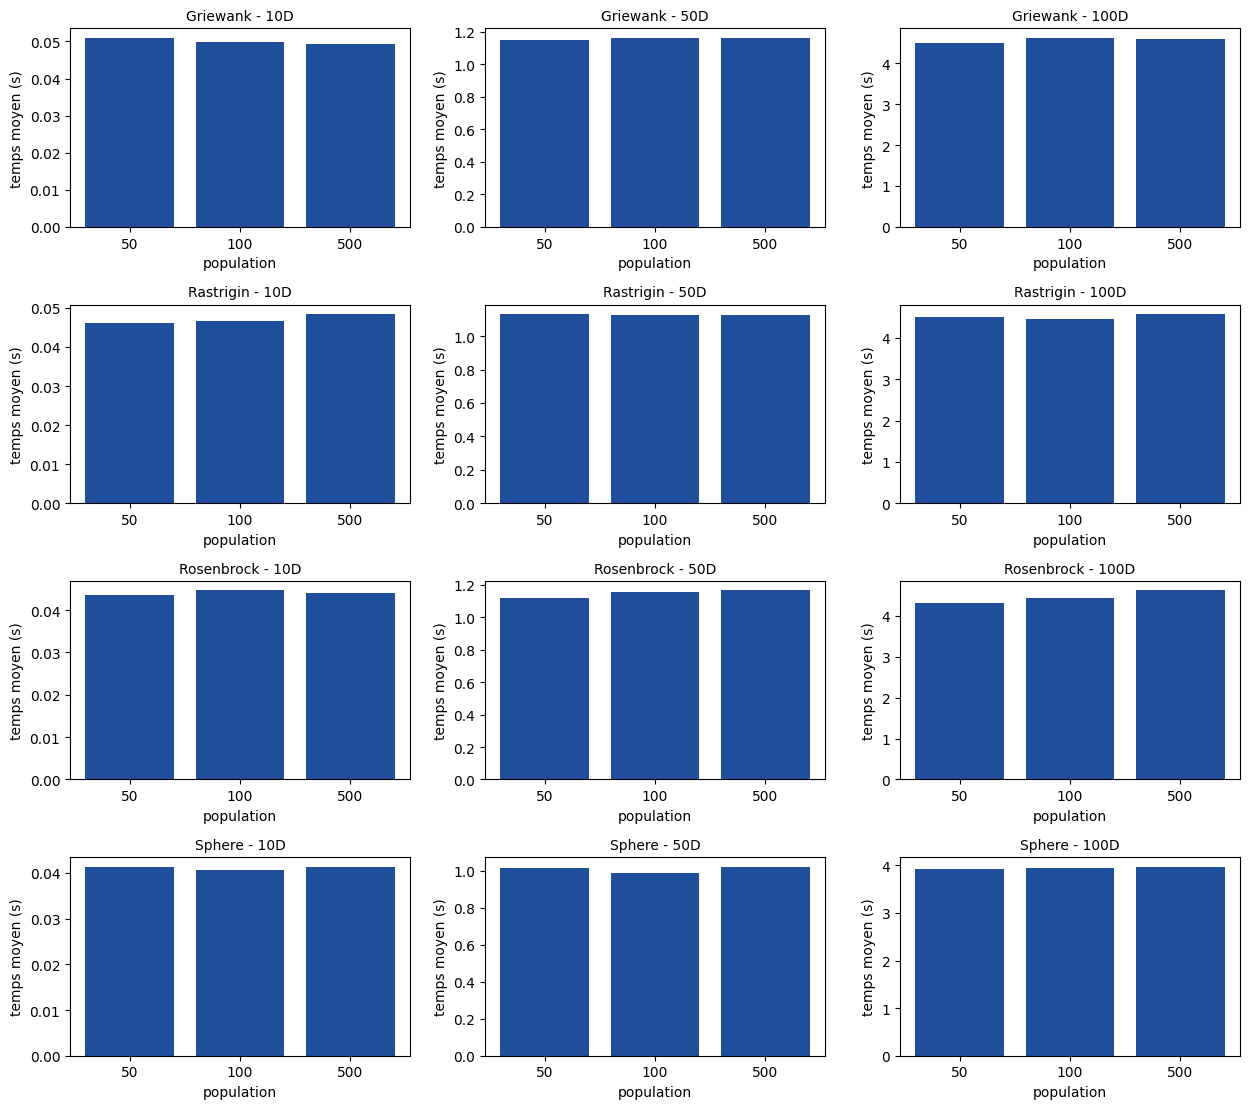

In [16]:
import matplotlib.pyplot as plt

funcs = list(summary_pso["func"].unique())
dims = sorted(summary_pso["dim"].unique())
pops = sorted(summary_pso["pop"].unique())

fig, axes = plt.subplots(len(funcs), len(dims), figsize=(4.2 * len(dims), 2.8 * len(funcs)), squeeze=False)

for i, f in enumerate(funcs):
    for j, d in enumerate(dims):
        # Filter for the specific function and dimension
        subset = summary_pso[(summary_pso.func == f) & (summary_pso.dim == d)]
        
        # Group by 'pop' and calculate the mean to combine duplicate rows
        s = subset.groupby("pop").mean(numeric_only=True).reindex(pops)
        
        ax = axes[i][j]
        ax.bar([str(p) for p in pops], s["time_s"], color="#1f4e9c")
        ax.set_title(f"{f} - {d}D", fontsize=10)
        ax.set_xlabel("population")
        ax.set_ylabel("temps moyen (s)")

plt.tight_layout()
plt.savefig("fig_time_vs_pop.png", dpi=200)
plt.show()